# Phase 4: Cross-lingual transfer (MuRIL, hi -> mr / bn)

Owner: Priyadarshi Kumar (Lead). Plan: [docs/01-roadmap.md](../docs/01-roadmap.md), Phase 4.

Take the three Hindi MuRIL checkpoints from Phase 3 (n=300,000, seeds 42, 43,
and 44, pinned revisions) and:

1. **Zero-shot** evaluate each on Marathi and Bengali gold (no further training).
   Hindi gold is scored first, and the run stops unless each model is within
   0.001 of its Phase 3 score.
2. Fine-tune MuRIL **in-language** on 300,000 `mr` and 300,000 `bn` sentences
   with the Phase 3 recipe, once per seed, to get the in-language baseline and
   the transfer gap with its seed-to-seed spread.

**Gate:** transfer matrix filled (train `hi`, test `hi`/`mr`/`bn`) **plus**
in-language upper bounds for `mr` and `bn`.

**Expected finding** ([docs/05-pitfalls.md](../docs/05-pitfalls.md)): hi -> mr
(same Devanagari script) should transfer better than hi -> bn (different
script). Measure it; that gap is the research angle for the writeup.

**How to run (Kaggle)**
1. Commit and push this notebook to `phase4-cross-lingual`, because the run
   clones that branch and records its commit.
2. Import it on Kaggle with **GPU T4 x2** and **Internet** on, and attach the
   `GH_TOKEN` (read-only) and `HF_TOKEN` (write) Secrets.
3. With `DEBUG = True`, use **Save & Run All**. This checks the full pipeline on
   tiny slices. Do not keep its `results.csv`.
4. Set `DEBUG = False` and use **Save & Run All** again (about 6.7 hours).
5. Download `NaamRekha/results/results.csv`,
   `NaamRekha/results/phase4_transfer_matrix.png`, and the executed notebook.
   Do not edit their contents.
6. Check the gate with `uv run python scripts/phase4_gate.py`.

In [1]:
# Pin versions (docs/04-compute.md), same pins as Phase 3.
%pip install -q transformers==5.22.1 datasets==5.1.0 accelerate==1.15.0 seqeval==1.2.2 sentencepiece==0.2.2  # Jupyter "magic" command: pip-installs the exact same pinned versions as Phase 3, so this phase is reproducible on the same library set

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64  # standard library: used below to base64-encode the GitHub token into an HTTP Basic auth header for the git clone
import os  # standard library: used for path checks, environment variables, and directory creation throughout this cell
import subprocess  # standard library: used to shell out to `git clone` and `git rev-parse` so the notebook can self-bootstrap the repo
import sys  # standard library: used to prepend the repo root to sys.path so `from src import ...` resolves

# Train on one GPU so per_device_train_batch_size is the real batch size.
# Kaggle's 2x T4 otherwise triggers DataParallel and silently doubles it.
# Must be set before torch is imported.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # restrict the process to GPU 0 only, so Kaggle's second T4 is invisible and Trainer can't silently wrap the model in DataParallel; set here, before torch is ever imported
## Why this must happen before torch is imported/touches CUDA: CUDA locks in the visible device list the first time any CUDA call reaches the driver; setting this after that point is silently ignored for the rest of the process, so it is placed as the very first statement in this bootstrap cell, ahead of every import that could trigger CUDA init.
## What breaks without it: Trainer would see both of Kaggle's T4s and wrap the model in DataParallel, silently doubling the effective batch size beyond BATCH_SIZE and invalidating the batch_size/effective_bs values logged for every in-language run in this phase.

REPO_URL = "https://github.com/iPriyadarshi/NaamRekha.git"  # HTTPS clone URL of this project's GitHub repo, used only when running on Kaggle/Colab where the repo isn't already present
REPO_BRANCH = "phase4-cross-lingual"  # the branch this notebook belongs to; Kaggle clones exactly this branch so the run matches the code that was committed


def get_secret(name):  # looks up a named secret (e.g. GH_TOKEN, HF_TOKEN) across whichever platform this notebook happens to be running on
    # Kaggle Secret, then Colab Secret, then environment variable.
    try:  # first try Kaggle's secrets vault, since that's where this notebook is meant to run for real training
        from kaggle_secrets import UserSecretsClient  # this import only succeeds inside a Kaggle kernel
        return UserSecretsClient().get_secret(name)  # fetch the named secret from Kaggle's attached Secrets (e.g. GH_TOKEN, HF_TOKEN)
    except Exception:  # not running on Kaggle (or secret not attached) -- fall through to the next source
        pass  # swallow the error and continue to the Colab branch below
    try:  # next try Google Colab's userdata secret store
        from google.colab import userdata  # this import only succeeds inside a Colab runtime
        return userdata.get(name)  # fetch the named secret from Colab's userdata API
    except Exception:  # not running on Colab either -- fall back to a plain environment variable
        return os.environ.get(name)  # local/dev fallback: read the secret from the process environment (e.g. a .env file), or None if unset


# Local: the notebook runs from notebooks/, so the repo root is "..".
# Colab/Kaggle: clone the repo next to the notebook. Check for a repo file, not
# just src/, because Kaggle has its own unrelated /kaggle/src folder.
if os.path.isfile("../src/data.py"):  # running from notebooks/ with the repo already checked out one directory up (the normal local layout)
    REPO_ROOT = os.path.abspath("..")  # repo root is the parent directory of notebooks/
elif os.path.isfile("src/data.py"):  # or the notebook has been moved so the repo root IS the current directory
    REPO_ROOT = os.path.abspath(".")  # repo root is the current working directory
else:  # neither local layout found -- assume we're on Kaggle/Colab where the repo must be cloned fresh
    REPO_ROOT = os.path.abspath("NaamRekha")  # the clone will be placed in a NaamRekha/ folder next to the notebook
    if not os.path.isdir(REPO_ROOT):  # only clone if that folder doesn't already exist (so re-running this cell doesn't reclone)
        env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}  # copy the current environment and disable git's interactive credential prompt, so a missing/bad token fails fast instead of hanging
        token = get_secret("GH_TOKEN")  # fetch the read-only GitHub token (attached as a Kaggle/Colab secret) used to authenticate the clone
        if token:  # only build an auth header if a token was actually found
            # Passed through the environment so it is never saved in .git/config
            # (Kaggle keeps that folder as output) or printed if the clone fails.
            auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()  # build the base64 payload for an HTTP Basic 'x-access-token:<token>' credential, the format git expects for a bearer-style GitHub token over HTTPS
            env.update(GIT_CONFIG_COUNT="1",  # inject one extra git config value via environment variables rather than writing a credential to disk
                       GIT_CONFIG_KEY_0="http.https://github.com/.extraheader",  # the config key being set: an extra HTTP header git attaches to every request to github.com
                       GIT_CONFIG_VALUE_0=f"AUTHORIZATION: basic {auth}")  # the config value: the actual 'Authorization: Basic <base64>' header carrying the token
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, REPO_ROOT],  # shallow-clone (depth 1) just the target branch into REPO_ROOT, using the auth header set above if present
                       check=True, env=env)  # raise immediately if the clone fails, using the environment (with the injected auth header) built above
sys.path.insert(0, REPO_ROOT)  # make the repo's `src` package importable regardless of which of the three layouts above was used

hf_token = get_secret("HF_TOKEN")  # Hugging Face token (write access) needed to download the Phase 3 MuRIL checkpoints and to push the new in-language checkpoints trained here
if hf_token:  # only set it if a token was actually found (e.g. local runs without training don't need one)
    os.environ["HF_TOKEN"] = hf_token  # export it so huggingface_hub/transformers pick it up automatically for auth

GIT_COMMIT = subprocess.check_output(["git", "-C", REPO_ROOT, "rev-parse", "--short", "HEAD"], text=True).strip()  # record the short commit hash of the checked-out code; it gets stamped into every results.csv row so each score traces back to the exact code that produced it

from src import LABELS, evaluate, id2label, label2id, load_split, log_result, tag_distribution  # import this project's shared NER utilities now that REPO_ROOT is on sys.path: label vocabulary, the seqeval-based scorer, data loaders, and the results-logging helper

print("repo:", REPO_ROOT, "| commit:", GIT_COMMIT)  # sanity-check output: confirm which repo copy and which commit this run is actually using
print("labels:", LABELS)  # sanity-check output: confirm the NER label set (e.g. O, B-PER, I-PER, ...) matches expectations before any scoring starts


Cloning into '/kaggle/working/NaamRekha'...


repo: /kaggle/working/NaamRekha | commit: 1dab156
labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


## Config

Every knob is in this one cell. The three Hindi checkpoints, working subset size,
and training recipe are the final Phase 3 values
([docs/phase3/README.md](../docs/phase3/README.md)).

In [3]:
SEED = 42            # global default; each run below sets its own seed
SEEDS = [42, 43, 44]  # the three Phase 3 seeds whose Hindi checkpoints get evaluated/transferred in this phase
## Why these exact three values and not freshly drawn seeds: HI_MODELS below is keyed by these specific seed numbers, each pointing at that seed's pinned Phase 3 Hindi checkpoint -- using a different seed here would have no matching Hindi checkpoint to zero-shot evaluate in the loop further down.
DEBUG = False         # True: tiny slices, 1 epoch (pipeline check). False: real runs on Kaggle.

SOURCE_LANG = "hi"  # the language the three frozen Phase 3 MuRIL checkpoints were trained on -- Hindi
TARGET_LANGS = ["mr", "bn"]  # the two new languages this phase measures transfer into: Marathi (same Devanagari script as Hindi) and Bengali (different script)
EVAL_LANGS = [SOURCE_LANG, *TARGET_LANGS]  # every language this phase evaluates on: Hindi plus both target languages

MODEL_KEY = "MuRIL"  # short model key used in results.csv, matching Phase 3's naming
BASE_CHECKPOINT = "google/muril-base-cased"  # the underlying pretrained checkpoint every model in this phase is built from

# Phase 3 Hindi models, pinned to their exact uploaded revisions. Each zero-shot
# hi -> hi score must be within HI_REPRO_TOLERANCE of its logged Phase 3 gold F1.
HI_MODELS = {  # pinned Phase 3 MuRIL checkpoints, one per seed, identified by their exact Hugging Face repo and commit revision, plus the Phase 3 gold Hindi F1 each one must reproduce
    42: {"repo": "priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s42_bfd254ed",  # seed 42's repo id, on the line below: its exact pinned revision hash and its logged Phase 3 Hindi gold F1 to reproduce
         "revision": "de5204680ed4a8ab1ac842847df6866a6e2c9251", "gold_f1": 0.8274137068534269},  # continuation: seed 42's revision hash and its Phase 3 gold F1 score
    43: {"repo": "priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s43_223b5780",  # seed 43's repo id
         "revision": "f15d615b7d760d23af6c5aa111675f0d6be39c3d", "gold_f1": 0.824173091270828},  # continuation: seed 43's revision hash and its Phase 3 gold F1 score
    44: {"repo": "priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6",  # seed 44's repo id
         "revision": "aa2f28136b49859a460217190b85ebedfc625e32", "gold_f1": 0.8174346201743462},  # continuation: seed 44's revision hash and its Phase 3 gold F1 score
}  # end of the HI_MODELS mapping
## Why hardcode repo id, revision, and gold_f1 per seed instead of looking them up dynamically from results.csv: pinning the exact revision hash (not just the repo id) guarantees this phase always evaluates the literal Phase 3-trained weights frozen at hand-off time, immune to that Hub repo being pushed to again later; gold_f1 is carried along purely so the reproduction check right below has a concrete Phase 3 number to compare a fresh re-score against.
HI_REPRO_TOLERANCE = 0.001    # about two entities on the 1,929-entity Hindi gold set
## Why re-check Hindi reproduction at all, given the model is pinned by revision: pinning guarantees the weights are byte-identical, but this phase reloads them in full 32-bit precision for inference while Phase 3 scored under fp16 autocast -- this tolerance confirms that precision difference stays within noise rather than silently drifting the baseline every zero-shot and transfer-gap number in this notebook is measured against.
HI_SUBSET_SIZE = 300_000  # the Phase 3 training-set size these Hindi checkpoints were fine-tuned on, reused here as the in-language training size for mr/bn
HI_EPOCHS = 3  # the Phase 3 epoch count, reused when re-scoring/recording the Hindi checkpoints

# Phase 3 training recipe, used for the in-language runs.
TRAIN_SUBSET_SIZE = HI_SUBSET_SIZE  # alias: the in-language mr/bn training runs use the exact same subset size as the Phase 3 Hindi models, for a fair comparison
MAX_LENGTH = 128  # subword tokens per sentence, same budget as Phase 3
BATCH_SIZE = 32  # per-device training batch size, same as Phase 3 (and still the true effective batch size thanks to the single-GPU restriction above)
EVAL_BATCH_SIZE = 32  # batch size used only for inference/scoring, kept separate from training batch size
LR = 2e-5  # peak learning rate for fine-tuning, same as Phase 3
WARMUP_RATIO = 0.1  # fraction of total steps used to linearly warm up the learning rate
EPOCHS = 3  # number of training epochs for the in-language mr/bn runs

HF_PRIVATE = False    # visibility of the in-language checkpoint repos (DEBUG repos are always private)

if DEBUG:  # override the real settings above with a tiny, fast configuration when doing a pipeline smoke-test
    SEEDS = SEEDS[:2]    # two seeds are enough to exercise the per-seed loops
    TRAIN_SUBSET_SIZE = 80  # train on just 80 sentences so the whole pipeline runs in seconds/minutes instead of hours
    EPOCHS = 1  # a single epoch is enough to prove the training loop runs end-to-end; the resulting score is meaningless
    BATCH_SIZE = 8  # a small batch size so the debug run also works on CPU or a tiny GPU without running out of memory


In [4]:
import random  # Python's standard PRNG, seeded below and used by make_subset for reproducible subsetting

import numpy as np  # NumPy, seeded below for reproducibility in any numeric code that depends on its global RNG
import torch  # PyTorch, the deep-learning framework used for model training/inference in this notebook

random.seed(SEED)  # seed Python's random module so make_subset's sampling is reproducible run to run
np.random.seed(SEED)  # seed NumPy's global RNG for the same reason
torch.manual_seed(SEED)  # seed PyTorch's CPU RNG, affecting weight initialization and any CPU-side randomness
torch.cuda.manual_seed_all(SEED)  # seed PyTorch's CUDA RNG on all visible GPUs, for reproducible GPU-side randomness (e.g. dropout)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # pick the GPU if one is visible, otherwise fall back to CPU
print("torch", torch.__version__, "| device:", device, "| visible GPUs:", torch.cuda.device_count())  # log the torch version, chosen device, and GPU count so the executed notebook records what hardware actually ran this
if device.type == "cpu" and not DEBUG:  # warn only for a real (non-DEBUG) run, since DEBUG is expected to also work on CPU
    print("WARNING: no GPU. Use Kaggle for the real runs.")  # the actual warning message printed when running on CPU
if not DEBUG and torch.cuda.device_count() != 1:  # guard against accidentally running a real (non-DEBUG) job with zero or more than one visible GPU, which would break the effective-batch-size assumption
    raise RuntimeError(f"real runs need exactly one visible GPU, found {torch.cuda.device_count()}")  # fail fast with a clear message rather than silently training with the wrong effective batch size


def pick_storage() -> str:  # decide where trained checkpoints are written so they survive across a session (Kaggle's working dir is wiped between sessions; Drive/local checkpoints/ are not)
    # Persistent storage for checkpoints: Kaggle working dir, Google Drive, or local checkpoints/.
    if os.path.isdir("/kaggle/working"):  # detect that we're running inside a Kaggle kernel, which always has this working directory
        return "/kaggle/working/naamrekha"  # Kaggle persists /kaggle/working as the session's Output, so checkpoints saved here survive until the version finishes
    try:  # not on Kaggle -- try mounting Google Drive instead, for Colab persistence
        from google.colab import drive  # type: ignore  # only importable inside a Colab runtime; the type: ignore silences a missing-stub warning from the type checker
        drive.mount("/content/drive")  # prompts the user (interactively) to authorize and mount their Google Drive at /content/drive
        return "/content/drive/MyDrive/NaamRekha"  # store checkpoints in the user's Drive so they aren't lost when the Colab runtime recycles
    except ImportError:  # neither Kaggle nor Colab -- must be a local/dev environment
        return os.path.join(REPO_ROOT, "checkpoints")  # fall back to a checkpoints/ folder inside the repo itself


STORAGE = pick_storage()  # resolve the storage root once for this run, using whichever platform was detected above
os.makedirs(os.path.join(STORAGE, "phase4"), exist_ok=True)  # ensure the phase4 subfolder exists before any checkpoint is written into it
print("checkpoints ->", os.path.join(STORAGE, "phase4"))  # log the resolved checkpoint path so it's visible in the executed notebook's output

torch 2.11.0+cu130 | device: cuda | visible GPUs: 1
checkpoints -> /kaggle/working/naamrekha/phase4


In [5]:
# Check the HF Hub login before any training, so a missing token fails here
# rather than after a multi-hour run.
from huggingface_hub import HfApi  # low-level Hugging Face Hub client, used to create model repos, check login, and upload checkpoint folders

hf_api = HfApi()  # a reusable Hub API client for creating repos and uploading files
HF_NAMESPACE = hf_api.whoami()["name"]  # fails here, immediately, if HF_TOKEN is missing or invalid -- before any multi-hour training run gets a chance to start
print("HF Hub user:", HF_NAMESPACE)  # confirm which Hub account the checkpoints in this run will be uploaded under


HF Hub user: priyadarshi-su


## Data

Gold test sets for all three languages are always scored in full
([docs/03-conventions.md](../docs/03-conventions.md)). Silver train sets for
`mr`/`bn` are loaded only for the in-language runs.

In [6]:
def entity_report(rows, name):  # print a quick sanity summary of a set of rows: how many of each entity type, and what fraction of tokens/sentences actually contain an entity
    counts = tag_distribution(rows)  # tally how many tokens carry each BIO tag (e.g. 'O', 'B-PER', 'I-ORG', ...) across these rows
    total = sum(counts.values())  # total token count across all tags, used as the denominator for the 'O' percentage below
    ents = {t: counts.get(f"B-{t}", 0) for t in ("PER", "ORG", "LOC")}  # count of entity *spans* per type, approximated by counting B- (begin) tags for PER/ORG/LOC
    with_ent = sum(any(t != "O" for t in tags) for _, tags in rows)  # number of sentences that contain at least one non-'O' tag, i.e. at least one entity mention
    print(f"{name}: {len(rows):,} sentences | entities {ents} | O = {counts['O'] / total:.1%} of tokens | "  # print the sentence count, entity counts, and what fraction of tokens are the non-entity 'O' tag
          f"{with_ent / len(rows):.1%} of sentences have >=1 entity")  # continuation of the same print: what fraction of sentences have at least one entity


def make_subset(rows, n, seed=SEED):  # draw a reproducible random subset of n rows from a larger list of (words, tags) sentence pairs
    n = min(n, len(rows))  # never ask for more rows than actually exist
    idx = sorted(random.Random(seed).sample(range(len(rows)), n))  # pick n unique row indices with a seed-specific RNG (so each seed gets a different, but reproducible, sample) and sort them to keep the original sentence order
    return [rows[i] for i in idx]  # materialize the subset by indexing into the original rows


gold = {lang: load_split(lang, "test") for lang in EVAL_LANGS}  # load the fixed gold test set for every evaluated language (hi, mr, bn) up front -- these are always scored in full, never subsetted
for lang, rows in gold.items():  # walk each language's gold set
    entity_report(rows, f"{lang} gold test")  # sanity-print the entity density of each language's gold test set before any scoring begins

data/hi_IndicNER_v1.0.zip: reconstructing file:   0%|          |  0.00B / 82.3MB            

data/hi_IndicNER_v1.0.zip: downloading bytes:           |  0.00B            

data/mr_IndicNER_v1.0.zip: reconstructing file:   0%|          |  0.00B / 25.2MB            

data/mr_IndicNER_v1.0.zip: downloading bytes:           |  0.00B            

data/bn_IndicNER_v1.0.zip: reconstructing file:   0%|          |  0.00B / 65.8MB            

data/bn_IndicNER_v1.0.zip: downloading bytes:           |  0.00B            

hi gold test: 864 sentences | entities {'PER': 788, 'ORG': 521, 'LOC': 613} | O = 83.0% of tokens | 86.0% of sentences have >=1 entity
mr gold test: 1,060 sentences | entities {'PER': 696, 'ORG': 391, 'LOC': 569} | O = 78.0% of tokens | 74.2% of sentences have >=1 entity
bn gold test: 607 sentences | entities {'PER': 457, 'ORG': 207, 'LOC': 331} | O = 81.8% of tokens | 79.4% of sentences have >=1 entity


## Label alignment and prediction

Same code as Phase 3 ([docs/05-pitfalls.md](../docs/05-pitfalls.md)): each
word's label goes on its first real subword; other subwords and special tokens
get `-100`. Predictions are read from those same positions. Words lost to
truncation stay in the gold labels and count as predicted `O`. Every Phase 4
score comes from a freshly loaded model in full 32-bit precision, because the
object used for fp16 training keeps an autocast wrapper on its `forward`. The self-test
runs on a Marathi and a Bengali sentence, since those are the new scripts in
this phase.

In [7]:
from datasets import Dataset  # Hugging Face's `datasets` library, used to wrap the raw (words, tags) rows into a Dataset the Trainer API expects
from transformers import AutoTokenizer  # Hugging Face's auto-tokenizer loader, used to load MuRIL's tokenizer for both the Hindi checkpoints and the new in-language models


def label_positions(word_ids, tokens):  # compute, for each original word, which single subword *position* should carry that word's label (identical rule to Phase 3)
    # word -> position of the subword that carries its label: the first piece,
    # skipping a standalone SentencePiece "▁" when a real piece follows it.  # skipping a standalone SentencePiece '▁' when a real piece follows it.
    positions = {}  # maps a word index (from word_ids) to the chosen subword position for its label
    for pos, wid in enumerate(word_ids):  # walk every subword position alongside the word index it came from (None for special tokens)
        if wid is not None and (wid not in positions or tokens[positions[wid]] == "▁"):  # real word subword, and either we haven't picked a position for this word yet, or the one we picked so far is a bare '▁' placeholder that should be replaced by a real piece
            positions[wid] = pos  # record this subword position as the (current best) label-carrying position for word wid
    return positions  # hand back the word -> label-position mapping built above


def tokenize_and_align_labels(batch, tokenizer, max_length=MAX_LENGTH):  # tokenize a batch of word-tokenized sentences into subwords and build a matching, correctly-aligned label array for each
    enc = tokenizer(batch["words"], is_split_into_words=True, truncation=True, max_length=max_length)  # subword-tokenize already word-split input (is_split_into_words=True preserves the word boundaries the tokenizer needs for word_ids())
    all_labels = []  # will hold one list of subword-level label ids per sentence in the batch
    for i, tags in enumerate(batch["tags"]):  # process each sentence's gold word-level tags in turn, i being its position in the batch
        word_ids = enc.word_ids(batch_index=i)  # for this sentence, the subword-position -> original-word-index mapping (None for special tokens) that the tokenizer records
        labeled = set(label_positions(word_ids, enc.tokens(batch_index=i)).values())  # the specific subword positions (not word indices) that should receive a real label for this sentence
        label_ids = []  # subword-level label ids being built for this sentence, same length as word_ids
        for pos, wid in enumerate(word_ids):  # walk every subword position in this sentence
            if wid is None:  # a special token ([CLS], [SEP]) or padding -- has no corresponding word
                label_ids.append(-100)                  # [CLS] / [SEP] / padding
            elif pos in labeled:  # this is the one chosen subword that should carry word wid's label
                label_ids.append(label2id[tags[wid]])   # labeled subword of this word
            else:  # a continuation subword of a word that was already labeled at an earlier position
                label_ids.append(-100)                  # other subword
        all_labels.append(label_ids)  # store this sentence's finished label-id list
    enc["labels"] = all_labels  # attach the aligned labels to the tokenizer output so Trainer can read them alongside input_ids/attention_mask
    return enc  # hand back the batch encoding, now including the labels field


def to_hf_dataset(rows, tokenizer, max_length=MAX_LENGTH):  # convert this project's (words, tags) row format into a tokenized Hugging Face Dataset ready for Trainer
    ds = Dataset.from_dict({"words": [r[0] for r in rows], "tags": [r[1] for r in rows]})  # build a Dataset with one 'words' and one 'tags' column, pulled out of the (words, tags) tuples
    return ds.map(lambda b: tokenize_and_align_labels(b, tokenizer, max_length),  # apply the tokenize-and-align function to every row, in batches, via Dataset.map
                  batched=True, remove_columns=["words", "tags"])  # process in batches for speed, and drop the now-unneeded raw words/tags columns from the result


def predict_tags(model, tokenizer, rows, max_length=MAX_LENGTH, batch_size=EVAL_BATCH_SIZE):  # run a fine-tuned model over a list of (words, tags) rows and return gold vs. predicted word-level tag sequences, ready for seqeval scoring
    model.eval()  # switch to evaluation mode (disables dropout, uses running batch-norm stats) for deterministic inference
    dev = next(model.parameters()).device  # find out which device (cpu/cuda) the model's weights currently live on, so inputs can be moved to match
    y_true, y_pred = [], []  # accumulators: gold tag sequences and predicted tag sequences, one list per sentence, across the whole dataset
    for i in range(0, len(rows), batch_size):  # process rows in fixed-size batches for efficient GPU inference
        chunk = rows[i:i + batch_size]  # the current slice of (words, tags) rows being predicted
        enc = tokenizer([r[0] for r in chunk], is_split_into_words=True, truncation=True,  # tokenize this batch's word lists, preserving word boundaries for word_ids()
                        max_length=max_length, padding=True, return_tensors="pt").to(dev)  # pad all sentences in the batch to equal length, return PyTorch tensors, and move them onto the model's device
        with torch.no_grad():  # disable gradient tracking during inference, saving memory and compute since no backward pass is needed
            preds = model(**enc).logits.argmax(-1).cpu().numpy()  # run the forward pass and take the highest-scoring label id at every subword position, moving the result to CPU/NumPy for easy indexing
        for b, (_, tags) in enumerate(chunk):  # walk each sentence in the batch, b being its index within this batch, unpacking its gold tags
            pred_tags = ["O"] * len(tags)  # start with an all-'O' prediction the same length as the gold tags; only labeled subword positions will overwrite entries below
            for wid, pos in label_positions(enc.word_ids(batch_index=b), enc.tokens(batch_index=b)).items():  # walk each word's chosen label-carrying subword position, the exact same alignment rule used during training
                pred_tags[wid] = id2label[int(preds[b][pos])]  # overwrite that word's prediction with the model's predicted tag at its labeled subword position; words with no labeled position (e.g. truncated away) stay 'O'
            y_pred.append(pred_tags)  # store this sentence's word-level predicted tag sequence
            y_true.append(list(tags))  # store this sentence's gold tag sequence alongside it, for seqeval to compare
    return y_true, y_pred  # hand back parallel lists of gold and predicted tag sequences, in the format src.eval.evaluate expects


In [8]:
_tok = AutoTokenizer.from_pretrained(BASE_CHECKPOINT)  # load MuRIL's tokenizer once, shared across both target-language self-tests below
for lang in TARGET_LANGS:  # run the label-alignment self-test on each new-script target language (Marathi and Bengali), since Phase 3 only verified it on Hindi
    words, tags = gold[lang][0]  # grab the very first gold sentence for this language as a concrete, known example to check alignment against
    labels = to_hf_dataset([gold[lang][0]], _tok)[0]["labels"]  # run that single sentence through the real tokenize_and_align_labels pipeline, exactly as training/scoring will
    enc = _tok(words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)  # tokenize the same sentence directly (outside the dataset pipeline) so we have raw access to word_ids()/tokens() for the checks below
    word_ids = enc.word_ids()  # subword-position -> word-index mapping for this sentence, used to replay the alignment logic manually
    assert len(labels) == len(word_ids)  # basic sanity check: one label id per subword position, no off-by-one
    labeled = set(label_positions(word_ids, enc.tokens()).values())  # recompute, independently, which subword positions should be labeled, to cross-check against what the pipeline actually did
    for pos, wid in enumerate(word_ids):  # walk every subword position in this sentence
        if wid is None or pos not in labeled:  # a special token, or a continuation subword that wasn't chosen to carry the label
            assert labels[pos] == -100, f"{lang}: special/other subword must be -100"  # verify those positions are always ignored by the loss (-100)
        else:  # the chosen label-carrying subword for its word
            assert labels[pos] == label2id[tags[wid]], f"{lang}: labeled subword must carry the word's tag"  # verify it carries exactly the gold tag for that word, converted to its integer id
    unk = sum(t == _tok.unk_token_id for t in _tok(words, is_split_into_words=True)["input_ids"])  # count how many subwords came out as the tokenizer's [UNK] token -- a high count would signal MuRIL's vocabulary struggling with this script
    long = sum(len(_tok(w, is_split_into_words=True)["input_ids"]) > MAX_LENGTH for w, _ in gold[lang])  # count gold sentences in this language whose untruncated subword length exceeds MAX_LENGTH -- these would have tail words silently scored as predicted 'O'
    print(f"{lang} label-alignment self-test: PASSED ({len(words)} words -> {len(word_ids)} subwords, "  # report success for this language, including how many words expanded into how many subwords and how many became [UNK]
          f"{unk} [UNK]) | gold sentences > {MAX_LENGTH} subwords: {long} / {len(gold[lang])}")  # continuation: how many gold sentences in this language exceed the token budget, out of how many total


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

mr label-alignment self-test: PASSED (9 words -> 12 subwords, 0 [UNK]) | gold sentences > 128 subwords: 0 / 1060


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

bn label-alignment self-test: PASSED (3 words -> 6 subwords, 0 [UNK]) | gold sentences > 128 subwords: 1 / 607


## Logging

One helper so every row carries the same notes, including the code commit and
library versions. `DEBUG` rows are marked so the gate ignores them.

In [9]:
import transformers  # imported again here for its __version__, which gets stamped into every results.csv row written by this phase's record() helper


def record(seed, train_lang, test_lang, subset_size, epochs, scores, checkpoint_path, notes):  # a single shared logging helper so every Phase 4 row (zero-shot and in-language alike) carries the same structured notes
    notes = (f"phase=4; seed={seed}; {notes}; git={GIT_COMMIT}; torch={torch.__version__}; "  # start building the notes string: tag every row with which phase it came from, the seed, and whatever run-specific notes were passed in
             f"transformers={transformers.__version__}" + ("; DEBUG run -- not a real result" if DEBUG else ""))  # continuation: append the exact code commit and library versions, and flag DEBUG rows explicitly so the gate can filter them out
    log_result(model=MODEL_KEY, train_lang=train_lang, test_lang=test_lang, subset_size=subset_size,  # append one row to results/results.csv describing this training/test language pair, size, epochs, scores, checkpoint link, and notes
               epochs=epochs, scores=scores, checkpoint_path=checkpoint_path, notes=notes)  # continuation of the log_result(...) call: the metrics, the checkpoint path, and the notes string built above
    with open(os.path.join(REPO_ROOT, "results", "results.csv"), encoding="utf-8") as f:  # reopen the results file that log_result just wrote to, purely to display what was logged
        print(f.read().splitlines()[-1])  # print just the last line (the row this call added), as an immediate on-screen confirmation


## 1. Zero-shot transfer (train `hi`, test `hi` / `mr` / `bn`)

No training. For each seed, Hindi is scored first and must be within 0.001 of
that model's Phase 3 gold score. If it isn't, the run stops before logging that
seed's rows, because its `mr`/`bn` numbers couldn't be trusted either. Rows log
the score measured here, so a small difference from Phase 3 stays visible.
Phase 3 scored its model right after training, under fp16 autocast, so the
tolerance allows for a few near-tied predictions flipping in 32-bit.

In [10]:
import gc  # Python's garbage collector module, used after each Hindi checkpoint to help release GPU memory before loading the next seed's model

from transformers import AutoModelForTokenClassification  # loads a token-classification model (MuRIL with its fine-tuned head) from a Hugging Face Hub checkpoint

zero_shot = {}    # (seed, test language) -> scores  # will map (seed, test language) -> score dict for every zero-shot (and Hindi reproduction) result
for seed in SEEDS:  # run the whole zero-shot evaluation once per Phase 3 Hindi seed/checkpoint
    hi = HI_MODELS[seed]  # look up this seed's pinned Phase 3 checkpoint info (repo id, revision, expected gold F1)
    hi_tokenizer = AutoTokenizer.from_pretrained(hi["repo"], revision=hi["revision"])  # load the tokenizer from the exact pinned revision of this seed's Hindi checkpoint
    hi_model = AutoModelForTokenClassification.from_pretrained(hi["repo"], revision=hi["revision"]).to(device)  # load the fine-tuned model from that same exact pinned revision, in full 32-bit precision (no fp16), and move it to the active device
    assert hi_model.config.label2id == label2id, "checkpoint label map differs from src.label2id"  # safety check: make sure this checkpoint's label mapping actually matches the project's current label2id before trusting its predictions
        ## What breaks without this assert: if src.label2id were ever edited after Phase 3 training (a label added or reordered), predict_tags would still run without error, but it would translate this older model's output ids through the *new* mapping -- silently reinterpreting one entity type as another and corrupting every downstream score with no visible failure.
    hi_url = f"https://huggingface.co/{hi['repo']}/tree/{hi['revision']}"  # build a clickable, revision-pinned URL to this seed's Hindi checkpoint, for logging

    seed_scores = {}  # will hold this seed's score dict for every evaluated language (hi reproduction, then mr, then bn)
    for lang in EVAL_LANGS:  # score this one Hindi checkpoint on every evaluation language in turn
        rows = gold[lang][:50] if DEBUG else gold[lang]  # use a tiny 50-sentence slice in DEBUG mode for speed, the full gold set otherwise
        y_true, y_pred = predict_tags(hi_model, hi_tokenizer, rows)  # run the model over this language's gold rows to get aligned gold vs. predicted tag sequences
        seed_scores[lang] = evaluate(y_true, y_pred)  # compute the full seqeval score dict for this language
        if lang == SOURCE_LANG and not DEBUG and abs(seed_scores[lang]["F1_overall"] - hi["gold_f1"]) > HI_REPRO_TOLERANCE:  # only for the source language (Hindi), and only on real runs: verify this reload reproduces the Phase 3-logged gold F1 within tolerance
            raise RuntimeError(f"seed {seed}: hi -> hi scored {seed_scores[lang]['F1_overall']:.4f}, "  # fail loudly with both scores if the reload doesn't reproduce Phase 3 -- something is wrong with the pinned checkpoint or the scoring code
                        ## Why raise (stopping the whole run) rather than warn and continue scoring mr/bn for this seed: a Hindi mismatch means something about this specific reload is already wrong (wrong revision resolved, corrupted download, label-map drift) -- whatever caused Hindi to mis-score would equally invalidate the mr/bn zero-shot numbers computed from that same loaded model, so logging them would record untrustworthy results as if they were trustworthy.
                               f"Phase 3 logged {hi['gold_f1']:.4f}")  # continuation: show the Phase 3 logged score being compared against

    for lang, scores in seed_scores.items():  # now that every language has been scored for this seed, log one results row per language
        zero_shot[(seed, lang)] = scores  # keep this score in the zero_shot dict too, so the transfer-matrix cell later can read it back
        kind = "in-language (Phase 3 check)" if lang == SOURCE_LANG else "zero-shot"  # label the Hindi row as a reproduction check (it's training data seen in Phase 3), and the mr/bn rows as genuine zero-shot transfer
        record(seed, SOURCE_LANG, lang, HI_SUBSET_SIZE, HI_EPOCHS, scores, hi_url,  # log this (seed, language) result, tagged with the Hindi subset size/epochs the checkpoint was actually trained with
               f"{kind}; checkpoint={hi['repo']}; revision={hi['revision']}")  # continuation: embed which exact checkpoint and revision produced this score, for traceability

    del hi_model  # drop the reference to this seed's loaded model so its GPU memory can be reclaimed before the next seed
    gc.collect()  # force a garbage-collection pass to actually reclaim the now-unreferenced Python objects
    torch.cuda.empty_cache()  # release PyTorch's cached (but now-unused) GPU memory back to the OS/CUDA allocator, so the next seed's model has room
        ## Why all three of del / gc.collect() / empty_cache(), not just del: `del` only drops this name's reference to the model; PyTorch's own caching allocator keeps freed GPU blocks reserved for reuse rather than returning them to CUDA. gc.collect() forces collection of any reference cycles still keeping the model alive, and empty_cache() is what actually releases PyTorch's cached blocks back to the driver -- skipping either can leave the next seed's model load without enough free VRAM on a single T4.


config.json:   0%|          | 0.00/984 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.41M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  948MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (11 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  948MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MuRIL,hi,hi,300000,3,0.8815628815628814,0.7197170645446507,0.8218298555377207,0.8174346201743462,https://huggingface.co/priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6/tree/aa2f28136b49859a460217190b85ebedfc625e32,phase=4; seed=44; in-language (Phase 3 check); checkpoint=priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6; revision=aa2f28136b49859a460217190b85ebedfc625e32; git=1dab156; torch=2.11.0+cu130; transformers=5.22.1
MuRIL,hi,mr,300000,3,0.8962131837307152,0.6907730673316709,0.8576419213973798,0.8342721612807591,https://huggingface.co/priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6/tree/aa2f28136b49859a460217190b85ebedfc625e32,phase=4; seed=44; zero-shot; checkpoint=priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6; revision=aa2f28136b49859a460217190b85ebedfc625e32; git=1dab156; torch=2.11.0+cu130; transformers=5.22.1
MuRIL,hi,bn,300000,3,0.8521739130434783,0.7330097087378641,0.7962382445141067,0.8091370558375636

## 2. In-language baselines (train `mr` -> test `mr`, train `bn` -> test `bn`)

Same recipe and subset size as the Hindi models, run once per seed, so the only
planned difference from the zero-shot rows is the training language. After
training, each model is reloaded from its saved files and scored in full 32-bit,
the same way as the zero-shot models. Each run uploads its final model,
confirms the upload, logs a link pinned to that revision, and only then deletes
the local copy. If the upload fails, the run stops and the local folder stays.
`run_name` contains a config hash, so a run can only resume from a checkpoint
made with identical settings.

In [11]:
import gc  # Python's garbage collector module, used after each in-language training run to help release GPU memory
import hashlib  # used to build a short deterministic hash of each run's config, so a run can be identified and resumed safely
import json  # used to serialize the config dict into a canonical string before hashing it
import math  # used for math.ceil when computing the number of optimizer steps per epoch
import shutil  # used to delete a run's local checkpoint directory once it has been safely uploaded to the Hub

from transformers import DataCollatorForTokenClassification, Trainer, TrainingArguments  # pull in the pieces needed to build and run a token-classification fine-tuning job: the batch collator, the training loop, and its configuration object


def publish_checkpoint(ckpt_dir, run_name):  # upload a finished checkpoint folder to the Hugging Face Hub and verify the upload actually landed before trusting it (identical logic to Phase 3)
    repo_id = f"{HF_NAMESPACE}/naamrekha-{run_name}"  # the Hub repo id this run's checkpoint will live under, namespaced to the current user/org and this run's unique name
    hf_api.create_repo(repo_id, private=HF_PRIVATE or DEBUG, exist_ok=True)  # create the model repo if it doesn't already exist; DEBUG runs are always kept private regardless of HF_PRIVATE
    commit = hf_api.upload_folder(repo_id=repo_id, folder_path=ckpt_dir,  # upload every file in the checkpoint directory to the Hub repo in one commit
                                  ignore_patterns=["checkpoint-*", "runs/*"])  # skip Trainer's intermediate checkpoint-N/ subfolders and TensorBoard runs/ logs -- only the final saved model is needed on the Hub
    remote = {f.rfilename: f.size for f in hf_api.model_info(repo_id, revision=commit.oid, files_metadata=True).siblings}  # ask the Hub what actually landed at this exact commit: a map from uploaded filename to its reported byte size
    local_size = os.path.getsize(os.path.join(ckpt_dir, "model.safetensors"))  # the local weights file's size, used as the thing to compare against the remote copy
    if remote.get("model.safetensors") != local_size:  # the single most important check in this function: did the uploaded weights file actually match what we have locally?
        raise RuntimeError(f"upload to {repo_id} not confirmed; keeping {ckpt_dir}")  # fail loudly rather than deleting the only good copy of the weights -- the local checkpoint is left on disk for inspection/retry
    return repo_id, commit.oid  # hand back the Hub repo id and the exact commit (revision) that was verified, so the in-language result can be logged with a pinned link


def train_run(lang, subset_size, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, seed=SEED, resume=True):  # fine-tune a fresh MuRIL on one target language at one subset size/seed, exactly the Phase 3 recipe -- the shared entry point for every in-language run
    random.seed(seed)  # re-seed Python's RNG with this specific run's seed, so make_subset below is reproducible per-seed
    torch.manual_seed(seed)  # re-seed torch with this run's seed, so weight init and training randomness are also reproducible per-seed

    train = make_subset(load_split(lang, "train"), subset_size, seed)  # load the full silver training set for this target language and draw this run's specific subset at the requested size and seed
    entity_report(train, f"{lang} train subset")  # sanity-print the entity density of this subset before spending GPU time training on it

    tokenizer = AutoTokenizer.from_pretrained(BASE_CHECKPOINT)  # load a fresh tokenizer from the base MuRIL checkpoint (not from any Hindi fine-tune)
    model = AutoModelForTokenClassification.from_pretrained(  # load a fresh MuRIL with a new token-classification head sized for this project's label set -- always starting from the base checkpoint, never from a Hindi fine-tune
        BASE_CHECKPOINT, num_labels=len(label2id), id2label=id2label, label2id=label2id  # the checkpoint to load from, how many output classes the new head needs, and the label<->id mappings so the model's config is self-describing
            ## Why start every in-language run from BASE_CHECKPOINT (raw pretrained MuRIL) instead of from a Phase 3 Hindi-fine-tuned checkpoint: this run measures mr/bn's in-language upper bound in isolation; starting from a Hindi fine-tune would conflate "pure in-language fine-tuning" with "Hindi-then-target-language transfer", making the later transfer_gap = in_language_F1 - zero_shot_F1 comparison meaningless, since in_language would already carry some of the same Hindi knowledge zero_shot is meant to isolate.
    )  # end of the AutoModelForTokenClassification.from_pretrained(...) call
    train_ds = to_hf_dataset(train, tokenizer)  # tokenize and label-align this run's training subset into a Trainer-ready Dataset

    # transformers 5 dropped warmup_ratio, so convert the ratio to a step count.  # transformers 5 dropped the warmup_ratio argument, so it has to be converted into an explicit step count here
    n_gpu = max(torch.cuda.device_count(), 1)  # number of GPUs visible to this process (will be exactly 1 for real runs, per the earlier guard; at least 1 even on CPU to avoid dividing by zero)
    total_steps = math.ceil(len(train_ds) / (batch_size * n_gpu)) * epochs  # total optimizer steps across the whole run, used to size the warmup schedule
    warmup_steps = int(WARMUP_RATIO * total_steps)  # convert the configured warmup *ratio* into an explicit warmup *step count*, since this transformers version only accepts steps

    config = {"checkpoint": BASE_CHECKPOINT, "lang": lang, "n": len(train), "epochs": epochs, "lr": lr,  # collect every setting that defines this run's identity, so it can be hashed into a stable fingerprint
              "batch_size": batch_size, "seed": seed, "max_length": MAX_LENGTH, "gpus": n_gpu,  # continuation of the config dict: more identity-defining settings
              "warmup_steps": warmup_steps}  # final entry in the config dict, then close it
    config_hash = hashlib.sha1(json.dumps(config, sort_keys=True).encode()).hexdigest()[:8]  # deterministically hash the sorted config into a short 8-character fingerprint, so identical settings get the same hash and different settings get different hashes
    run_name = (f"{MODEL_KEY.lower()}_{lang}_n{len(train)}_e{epochs}_lr{lr}_s{seed}_{config_hash}"  # build a human-readable run name encoding the model, language, size, epochs, LR, and seed, plus the config hash for exactness
                + ("_debug" if DEBUG else ""))  # tag debug runs distinctly in their folder/checkpoint name so they're never confused with real runs
    ckpt_dir = os.path.join(STORAGE, "phase4", run_name)  # the local directory this specific run's checkpoints will be written to
    has_ckpt = os.path.isdir(ckpt_dir) and any(f.startswith("checkpoint-") for f in os.listdir(ckpt_dir))  # detect whether a matching in-progress checkpoint already exists (same config_hash means truly identical settings), so training can resume instead of restarting

    args = TrainingArguments(  # assemble Trainer's run configuration from the settings decided above
        output_dir=ckpt_dir,  # where Trainer writes its own checkpoint-N/ subfolders during training
        num_train_epochs=epochs,  # how many full passes over train_ds to run
        per_device_train_batch_size=batch_size,  # batch size per GPU; combined with the single-GPU guard above, this is the true effective batch size
        learning_rate=lr,  # peak learning rate for the optimizer
        warmup_steps=warmup_steps,  # number of initial steps over which the LR ramps up linearly from 0 to its peak
        fp16=torch.cuda.is_available(),  # use mixed-precision (16-bit) training when a GPU is available, for roughly 2x speed and lower memory use
        save_strategy="epoch",  # write a checkpoint once per epoch rather than on a fixed step interval
        save_total_limit=1,  # keep only the single most recent checkpoint on disk, since Kaggle storage is limited and older ones aren't needed once training is caught up
        logging_steps=50,  # emit a training-loss log line every 50 optimizer steps
        seed=seed,  # Trainer's own internal seed, for its data shuffling and any of its own randomness, kept consistent with this run's seed
        report_to=[],  # disable Trainer's automatic integration with tools like Weights & Biases/TensorBoard -- this project logs its own results.csv instead
    )  # end of the TrainingArguments(...) call
    trainer = Trainer(model=model, args=args, train_dataset=train_ds,  # assemble the Trainer with the model, its training config, and the tokenized dataset
                      data_collator=DataCollatorForTokenClassification(tokenizer), processing_class=tokenizer)  # continuation: the batch collator (padding inputs/labels for this tokenizer) and the tokenizer itself, so Trainer can save it alongside the model
    trainer.train(resume_from_checkpoint=has_ckpt and resume)  # run (or resume) the training loop; resumes from the last saved checkpoint only if one exists for this exact config and resume=True
    trainer.save_model(ckpt_dir)  # save the final model weights and config to ckpt_dir, on top of/after Trainer's own epoch checkpoints
    del trainer, model  # drop references to the trainer and model objects so Python can garbage-collect the GPU tensors they hold
    gc.collect()  # force a garbage-collection pass to actually reclaim the now-unreferenced Python objects
    torch.cuda.empty_cache()  # release PyTorch's cached (but now-unused) GPU memory back to the OS/CUDA allocator before reloading a fresh copy for scoring

    # Score a fresh copy: the trained object still has fp16 autocast on forward,
    # while the zero-shot models run in full 32-bit.  # while the zero-shot models run in full 32-bit.
    eval_tokenizer = AutoTokenizer.from_pretrained(ckpt_dir)  # reload the tokenizer fresh from the saved checkpoint directory, exactly as a later consumer of this checkpoint would
    eval_model = AutoModelForTokenClassification.from_pretrained(ckpt_dir).to(device)  # reload the model fresh from the saved checkpoint directory in full 32-bit precision, so its score is directly comparable to the zero-shot models
        ## Why reload a fresh copy from disk to score instead of scoring the just-trained `model`/`trainer` object directly: Trainer leaves its in-memory model wrapped for fp16 mixed-precision (autocast), while every zero-shot Hindi score in this phase is produced by a freshly loaded, full 32-bit model; reloading here keeps the in-language scores measured under the same numerical conditions as the zero-shot scores they are compared against.
    rows = gold[lang][:50] if DEBUG else gold[lang]  # use a tiny 50-sentence slice in DEBUG mode for speed, the full gold set otherwise
    y_true, y_pred = predict_tags(eval_model, eval_tokenizer, rows)  # run the freshly-reloaded model over this language's gold rows to get aligned gold vs. predicted tag sequences
    scores = evaluate(y_true, y_pred)  # compute the full seqeval score dict for this in-language run -- the number that becomes this language's in-language upper bound

    repo_id, revision = publish_checkpoint(ckpt_dir, run_name)  # upload the checkpoint to the Hub and get back its verified repo id and commit revision
    checkpoint_url = f"https://huggingface.co/{repo_id}/tree/{revision}"  # build a clickable, revision-pinned URL to the exact uploaded checkpoint

    record(seed, lang, lang, len(train), epochs, scores, checkpoint_url,  # log this in-language result: train language and test language are the same, confirming this is the in-language (not transfer) condition
           f"in-language baseline; lr={lr}; bs={batch_size}; effective_bs={batch_size * n_gpu}; gpus={n_gpu}; "  # continuation: start the notes string with the run's label and core hyperparameters
           f"warmup_steps={warmup_steps}; epochs={epochs}; max_len={MAX_LENGTH}; checkpoint={BASE_CHECKPOINT}; "  # continuation: more run settings appended to the notes string
           f"config={config_hash}")  # final entry in the notes string: the config fingerprint

    shutil.rmtree(ckpt_dir)  # now that the checkpoint is verified on the Hub and logged, delete the local copy to free Kaggle's limited disk space
    print(f"published {checkpoint_url} and removed the local copy")  # confirm both the publish and the cleanup happened, in order

    del eval_model  # drop the reference to the evaluation copy of the model so its GPU memory can be reclaimed
    gc.collect()  # force a garbage-collection pass to actually reclaim the now-unreferenced Python objects
    torch.cuda.empty_cache()  # release PyTorch's cached (but now-unused) GPU memory back to the OS/CUDA allocator, so the next run in this loop has room
    return scores, checkpoint_url  # hand back this run's scores and its pinned checkpoint URL to the caller


in_language = {}    # (seed, language) -> scores  # will map (seed, target language) -> score dict for every in-language baseline trained in this cell
for seed in SEEDS:  # train one in-language baseline per seed, for reproducibility of the baseline itself
    for lang in TARGET_LANGS:  # and one per target language (Marathi and Bengali)
        in_language[(seed, lang)], _ = train_run(lang, TRAIN_SUBSET_SIZE, seed=seed)  # train MuRIL from scratch on this language/seed and keep only the score dict (the checkpoint URL is already logged inside train_run)


mr train subset: 300,000 sentences | entities {'PER': 226058, 'ORG': 108652, 'LOC': 147620} | O = 78.2% of tokens | 80.4% of sentences have >=1 entity


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ig

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

... (55 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MuRIL,bn,bn,300000,3,0.8642241379310345,0.7427184466019418,0.7932098765432098,0.8158953722334004,https://huggingface.co/priyadarshi-su/naamrekha-muril_bn_n300000_e3_lr2e-05_s44_e7b8f845/tree/1d47716a7955c090b1d72b5fbc48b7f218605a76,phase=4; seed=44; in-language baseline; lr=2e-05; bs=32; effective_bs=32; gpus=1; warmup_steps=2812; epochs=3; max_len=128; checkpoint=google/muril-base-cased; config=e7b8f845; git=1dab156; torch=2.11.0+cu130; transformers=5.22.1
published https://huggingface.co/priyadarshi-su/naamrekha-muril_bn_n300000_e3_lr2e-05_s44_e7b8f845/tree/1d47716a7955c090b1d72b5fbc48b7f218605a76 and removed the local copy


## 3. Transfer matrix and gap

Rows = training language, columns = test language, showing the mean across
seeds. The **transfer gap** for a target language is `in-language F1 - zero-shot
F1`, computed per seed and then summarized by its mean, standard deviation, and
per-seed values. A gap whose sign changes across seeds is not established.

mean F1_overall across seeds:
test       hi      mr      bn
train                        
hi     0.8228  0.8332  0.8037
mr        NaN  0.8163     NaN
bn        NaN     NaN  0.8132

standard deviation across seeds:
test      hi      mr      bn
train                       
hi     0.005  0.0030  0.0055
mr       NaN  0.0007     NaN
bn       NaN     NaN  0.0030

mean and standard deviation by entity type:
  hi -> hi: F1_PER 0.8867 +/- 0.0047 | F1_ORG 0.7323 +/- 0.0123 | F1_LOC 0.8210 +/- 0.0020 | F1_overall 0.8228 +/- 0.0050
  hi -> mr: F1_PER 0.8989 +/- 0.0037 | F1_ORG 0.6883 +/- 0.0022 | F1_LOC 0.8525 +/- 0.0062 | F1_overall 0.8332 +/- 0.0030
  hi -> bn: F1_PER 0.8505 +/- 0.0017 | F1_ORG 0.7180 +/- 0.0193 | F1_LOC 0.7923 +/- 0.0034 | F1_overall 0.8037 +/- 0.0055
  mr -> mr: F1_PER 0.8884 +/- 0.0038 | F1_ORG 0.6519 +/- 0.0093 | F1_LOC 0.8432 +/- 0.0024 | F1_overall 0.8163 +/- 0.0007
  bn -> bn: F1_PER 0.8585 +/- 0.0081 | F1_ORG 0.7345 +/- 0.0100 | F1_LOC 0.7983 +/- 0.0045 | F1_overall 0.81

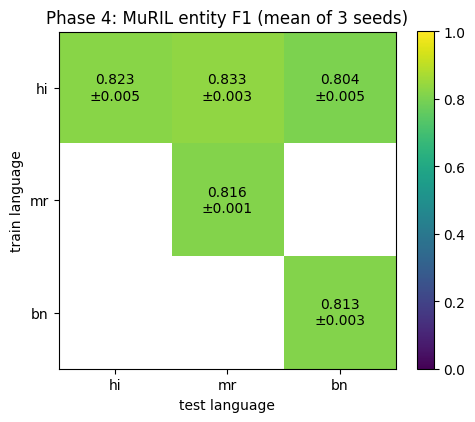

In [12]:
import matplotlib.pyplot as plt  # plotting library used to draw the transfer-matrix heatmap
import pandas as pd  # used to build the transfer matrix and spread tables as DataFrames


def mean_sd(values):  # compute the mean and sample standard deviation of a list of scores -- the standard summary used throughout this cell
    values = np.array(values, dtype=float)  # convert to a NumPy array of floats so .mean()/.std() are available
    return values.mean(), (values.std(ddof=1) if len(values) > 1 else 0.0)  # sample standard deviation (ddof=1); falls back to 0.0 when there's only one value, since variance is undefined for a single sample


cell_scores = {(SOURCE_LANG, lang): [zero_shot[(s, lang)] for s in SEEDS] for lang in EVAL_LANGS}  # for Hindi as the training language, gather each evaluation language's zero-shot scores across all three seeds -- this is the top row of the transfer matrix
## Why include (hi, hi) in cell_scores at all, when Hindi isn't a transfer result: it fills the matrix's own reference cell, showing Hindi's ceiling under the exact same scoring code and precision as every other cell, so a reader can see at a glance how far hi->mr and hi->bn fall below Hindi's own best case, not only below each other.
cell_scores.update({(lang, lang): [in_language[(s, lang)] for s in SEEDS] for lang in TARGET_LANGS})  # for each target language trained in-language, gather its own in-language scores across all three seeds -- these are the matrix's diagonal cells for mr/bn

matrix = pd.DataFrame(np.nan, index=EVAL_LANGS, columns=EVAL_LANGS)  # a train-language x test-language matrix of mean F1, initialized to NaN so unfilled cells (e.g. mr trained -> bn tested, never run) are visibly empty
spread = matrix.copy()  # a matching matrix holding each filled cell's standard deviation across seeds
for (train_lang, test_lang), scores in cell_scores.items():  # walk every (train_lang, test_lang) cell that actually has data
    matrix.loc[train_lang, test_lang], spread.loc[train_lang, test_lang] = mean_sd([s["F1_overall"] for s in scores])  # fill in this cell's mean and standard deviation of F1_overall across the seeds that ran it
matrix.index.name, matrix.columns.name = "train", "test"  # label the matrix's axes for readability when printed
spread.index.name, spread.columns.name = "train", "test"  # label the spread matrix's axes the same way
print("mean F1_overall across seeds:")  # header line before printing the mean matrix
print(matrix.round(4).to_string())  # print the mean F1 matrix rounded to 4 decimal places
print("\nstandard deviation across seeds:")  # header line before printing the standard-deviation matrix
print(spread.round(4).to_string())  # print the standard-deviation matrix rounded to 4 decimal places

print("\nmean and standard deviation by entity type:")  # header line before the more detailed per-entity-type breakdown
for (train_lang, test_lang), scores in cell_scores.items():  # walk every filled (train_lang, test_lang) cell again, this time for a per-entity-type breakdown
    parts = [f"{k} {mean_sd([s[k] for s in scores])[0]:.4f} +/- {mean_sd([s[k] for s in scores])[1]:.4f}"  # format each entity type's mean +/- standard deviation across seeds
             for k in ("F1_PER", "F1_ORG", "F1_LOC", "F1_overall")]  # the four metrics broken out per cell: per-type F1 for PER/ORG/LOC plus the overall F1
    print(f"  {train_lang} -> {test_lang}: " + " | ".join(parts))  # print this cell's breakdown as one line, train language -> test language, with every metric

print("\ntransfer gap (in-language - zero-shot), paired by seed:")  # header line before the transfer-gap report, the key research result of this phase
for lang in TARGET_LANGS:  # compute the transfer gap only for the two target (non-Hindi) languages
    for k in ("F1_PER", "F1_ORG", "F1_LOC", "F1_overall"):  # report the gap for every metric, not just overall F1, so e.g. a script-specific entity type can be inspected separately
        gaps = [in_language[(s, lang)][k] - zero_shot[(s, lang)][k] for s in SEEDS]  # per-seed transfer gap: this seed's in-language score for this metric minus its zero-shot score, paired within the same seed so the comparison isn't confounded by seed-to-seed noise
                ## Why subtract per matching seed index and then summarize, rather than subtracting the two already-computed mean scores: in_language[(s,...)] and zero_shot[(s,...)] come from two different models that merely share a seed *index*, not a common random draw; keeping the subtraction per-index (and printing gap_sd and every individual value) is what lets a reader see whether the gap's sign is stable across all three seeds or flips, which subtracting two pre-averaged means would hide.
        gap_mean, gap_sd = mean_sd(gaps)  # mean and standard deviation of the per-seed gaps -- a gap whose sign flips across seeds is not a reliable finding
        print(f"  hi -> {lang} {k}: mean {gap_mean:+.4f}, sd {gap_sd:.4f}, per seed "  # print the mean gap (signed, so a negative gap would show zero-shot beating in-language) and its standard deviation
              + ", ".join(f"{s}: {g:+.4f}" for s, g in zip(SEEDS, gaps)))  # continuation: list every individual seed's gap value, so the reader can see the spread directly rather than trusting only the summary

fig, ax = plt.subplots(figsize=(5, 4.2))  # create a new figure and axes sized for a compact heatmap
im = ax.imshow(matrix.values, vmin=0, vmax=1, cmap="viridis")  # draw the mean-F1 matrix as a heatmap, with a fixed 0-to-1 color scale so colors are comparable to other phases' figures
## Why fix vmin=0, vmax=1 instead of letting imshow auto-scale to this matrix's own min/max: this heatmap is meant to be visually comparable, at a glance, against other F1 figures in the written report; auto-scaling would map the same F1 value to a different color depending on what else happens to be in this particular matrix's data range.
ax.set_xticks(range(len(EVAL_LANGS)), EVAL_LANGS)  # label the x-axis ticks with the test languages, in the fixed hi/mr/bn order
ax.set_yticks(range(len(EVAL_LANGS)), EVAL_LANGS)  # label the y-axis ticks with the train languages, same fixed order
ax.set_xlabel("test language")  # axis label clarifying that columns are the test language
ax.set_ylabel("train language")  # axis label clarifying that rows are the train language
for i in range(len(EVAL_LANGS)):  # walk every row of the matrix by index
    for j in range(len(EVAL_LANGS)):  # walk every column of the matrix by index
        v = matrix.values[i, j]  # this cell's mean F1 value
        if not np.isnan(v):  # only annotate cells that actually have data (skip the NaN cells with no run, e.g. mr trained -> bn tested)
            ax.text(j, i, f"{v:.3f}\n\u00b1{spread.values[i, j]:.3f}", ha="center", va="center",  # write the mean F1 and its +/- standard deviation as text inside this heatmap cell
                    color="white" if v < 0.6 else "black")  # continuation: switch text color to stay readable against both dark and light cell backgrounds
ax.set_title(f"Phase 4: MuRIL entity F1 (mean of {len(SEEDS)} seeds)")  # title the figure with the model and how many seeds its means are averaged over
fig.colorbar(im, ax=ax)  # add a color bar showing how the color scale maps to F1 values
fig.tight_layout()  # adjust spacing automatically so labels/title aren't clipped
fig_path = os.path.join(REPO_ROOT, "results", "phase4_transfer_matrix.png")  # the fixed output path the gate script and README expect this figure at
fig.savefig(fig_path, dpi=150)  # write the figure to disk at a resolution suitable for a report/README
print("saved", fig_path)  # confirm where the figure was written


## Gate

```
uv run python scripts/phase4_gate.py
```

Checks that this notebook ran once from a fresh kernel; that all 15 required
rows (five matrix cells on three seeds) are logged once each from one code
commit and match its output; that the Hindi rows use the pinned Phase 3
checkpoints and are within 0.001 of their scores; that the in-language runs use the
Phase 3 size and single-GPU setup with pinned checkpoints; and that
[docs/phase4/README.md](../docs/phase4/README.md) reports each cell's mean.